# Gewogen voting en eerlijke vergelijking

Lesbasis: **4 — Models**, dia 36 en 38 over ensembles en bagging. Soft voting middelt kansen; de vaste kandidaatgewichten worden op binnen-OOF gekozen.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'results_v3/run.json').exists())
sys.path.insert(0, str(HERE))
from mushroom_alternative import development_data, scores
from improve_v3 import experiments, InputFeatures, WEIGHTS
from build_v3_reports import label
X, y, ids, folds = development_data()
summary = pd.read_csv(HERE/'results_v3/summary.csv').set_index('model')
details = pd.read_csv(HERE/'results_v3/outer_fold_metrics.csv')
predictions = pd.read_csv(HERE/'results_v3/outer_oof_predictions.csv', float_precision='round_trip')
selections = json.loads((HERE/'results_v3/selections.json').read_text())
assert len(summary) == 14 and summary.folds.eq(5).all()


In [2]:
print('Vaste gewichten RF / LightGBM / CatBoost:', WEIGHTS)
display(pd.DataFrame([s for s in selections if s['family']=='voting']))

Vaste gewichten RF / LightGBM / CatBoost: [(1.0, 0.0, 0.0), (0.0, 1.0, 0.0), (0.0, 0.0, 1.0), (0.5, 0.5, 0.0), (0.5, 0.0, 0.5), (0.0, 0.5, 0.5), (0.3333333333333333, 0.3333333333333333, 0.3333333333333333)]


,family,fold,weights,inner_oof_macro_f1,f1_threshold,fpr_threshold
0,voting,1,"[1.0, 0.0, 0.0]",0.763727,0.49,0.462181
1,voting,2,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.768752,0.49,0.484154
2,voting,3,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.766714,0.49,0.488511
3,voting,4,"[0.5, 0.5, 0.0]",0.753942,0.51,0.500091
4,voting,5,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.769087,0.47,0.483998


Een gewicht van één voor RF betekent dat de andere modellen in die fold niet helpen volgens de trainingsselectie. Een ingewikkelder ensemble verdient geen voorkeur zonder voldoende winst.

In [3]:
paired = details.pivot(index='fold', columns='model', values='macro_f1')
delta = paired.subtract(paired['rf_compatible_f1_threshold'], axis=0)
display(delta.round(4))
display(pd.DataFrame({'gemiddeld_verschil': delta.mean(), 'folds_beter_dan_v2': (delta>0).sum()}))

model,catboost_default,catboost_f1,catboost_fpr_budget,lightgbm_default,lightgbm_f1,lightgbm_fpr_budget,rf300_reference_default,rf_compatible_f1_threshold,rf_selection_default,rf_selection_f1,rf_selection_fpr_budget,voting_default,voting_f1,voting_fpr_budget
fold,,,,,,,,,,,,,,
1,-0.0072,-0.0103,-0.0132,-0.0081,-0.0100,-0.0031,-0.0064,0.0,0.0173,0.0146,0.0121,0.0173,0.0146,0.0121
2,0.0173,0.0173,0.0103,0.0028,0.0100,0.0071,0.0048,0.0,0.0058,-0.0040,0.0013,0.0197,0.0077,0.0080
3,-0.0180,-0.0248,-0.0153,-0.0108,-0.0090,-0.0062,-0.0142,0.0,-0.0117,-0.0117,-0.0004,0.0020,0.0053,0.0056
4,-0.0498,-0.0471,-0.0422,-0.0312,-0.0237,-0.0135,-0.0119,0.0,-0.0035,-0.0115,-0.0036,-0.0092,-0.0021,-0.0092
5,-0.0099,-0.0085,-0.0110,0.0073,0.0015,-0.0011,-0.0085,0.0,0.0211,0.0122,0.0175,0.0189,0.0229,0.0214


,gemiddeld_verschil,folds_beter_dan_v2
model,,
catboost_default,-0.013526,1
catboost_f1,-0.014679,1
catboost_fpr_budget,-0.014279,1
lightgbm_default,-0.008019,2
lightgbm_f1,-0.006244,2
lightgbm_fpr_budget,-0.003350,1
rf300_reference_default,-0.007249,1
rf_compatible_f1_threshold,0.000000,0
rf_selection_default,0.005799,3


## Fouten vergelijken

Iedere punt gebruikt dezelfde 4.100 buitenfoldrijen. Lager en meer naar links betekent minder fouten van beide typen. Dit is een beschrijvende vergelijking; geen gecorrigeerde significantietoets na meerdere studies.

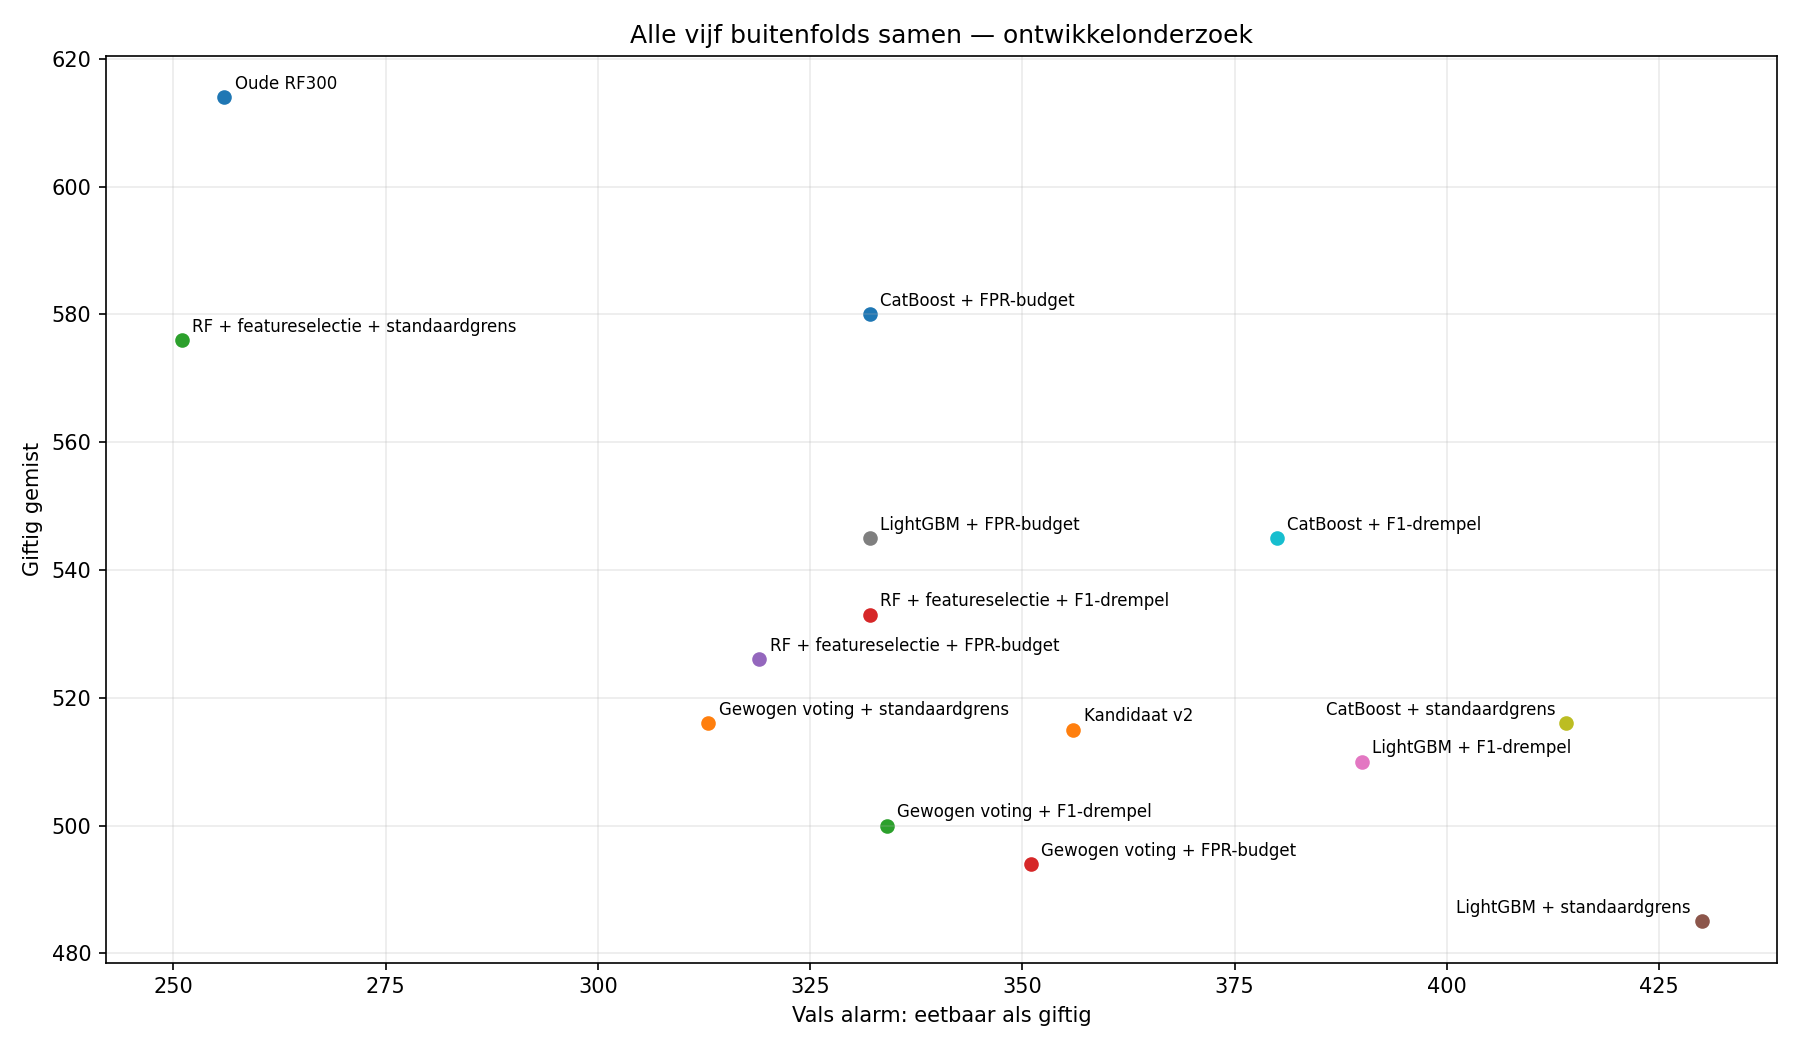

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
fig, ax = plt.subplots(figsize=(12,7))
for name, row in summary.iterrows():
    ax.scatter(row.fp_total, row.fn_total)
    right = row.fp_total > 390
    ax.annotate(label(name), (row.fp_total, row.fn_total), xytext=(-5 if right else 5,4), ha='right' if right else 'left', textcoords='offset points', fontsize=8)
ax.set(xlabel='Vals alarm: eetbaar als giftig', ylabel='Giftig gemist', title='Alle vijf buitenfolds samen — ontwikkelonderzoek')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(HERE/'results_v3/foutenvergelijking.png', dpi=150)
plt.close(fig)
display(Image(filename=str(HERE/'results_v3/foutenvergelijking.png')))

In [5]:
display(json.loads((HERE/'results_v3/decision.json').read_text()))

{'performance_goal_met': True,
 'goal_qualifying_procedures': ['voting_f1', 'voting_fpr_budget'],
 'highest_macro_f1': 'voting_default',
 'best_goal_qualifying_procedure': 'voting_f1',
 'selection_scope': 'Exploratory comparison after completing all prespecified folds; no independent test.',
 'production_changed': False,
 'test_rows_scored': 0}

De uiteindelijke kandidaat wordt op ontwikkelbewijs gekozen. Een betrouwbaar eindcijfer vereist later nieuwe data; de al bekeken 900 records worden daarvoor niet hergebruikt.